A **Multilayer Perceptron (MLP)** is a fundamental class of feedforward artificial neural network (ANN). It serves as the baseline architecture for deep learning, forming the building blocks of more complex models like Convolutional Neural Networks (CNNs) and Transformers.

An MLP consists of at least three fully connected layers of nodes: an **input layer**, one or more **hidden layers**, and an **output layer**. Except for the input nodes, every node is a neuron that uses a nonlinear activation function.

![Neural network pipeline featuring a Multilayer Perceptron (MLP). Source: Made with Google AI](https://encrypted-tbn0.gstatic.com/licensed-image?q=tbn:ANd9GcQwqdFmg0GoTvf1VngHzXOGwsRPdaVAIs-O5FU5KOzpKMNM4HnIMcRJRmNnahRpzUszv5q3IMYoEZSHMns)

---

### Key Architectural Components

* **Input Layer:** Receives the raw feature vector (e.g., pixel values, numerical features, or embeddings) and passes them forward without performing any mathematical transformations.
* **Hidden Layer(s):** Positioned between the input and output layers, these intermediate layers extract hierarchical features and complex patterns from the data.
* **Output Layer:** Produces the final prediction, whether it is a continuous value (regression) or class probabilities (classification).
* **Weights and Biases ($\mathbf{W}$ and $\mathbf{b}$):** Parameters adjusted during training to minimize the error of the network's predictions.
* **Activation Functions:** Nonlinear functions (such as ReLU, GeLU, Tanh, or Sigmoid) applied to the output of each neuron, allowing the network to learn complex, non-linear decision boundaries.

---

### How an MLP Learns

1. **Forward Propagation:** Data flows from the input layer through the weighted connections of the hidden layers to the output layer, generating a prediction.
2. **Loss Calculation:** A loss function (e.g., Mean Squared Error or Cross-Entropy Loss) measures the difference between the predicted output and the ground truth.
3. **Backpropagation & Optimization:** Using the chain rule of calculus, the gradient of the loss function is computed backward through the network, and optimization algorithms (like Adam or SGD) update the weights and biases to reduce future errors.

The training of a Multilayer Perceptron (MLP) relies on two core phases: **Forward Propagation** (making predictions and measuring error) and **Backpropagation with Gradient Descent** (distributing the error backward and updating parameters).

![Visualizing the forward and backward propagation flow across neural network layers. Source: atdigit / Getty Images](https://encrypted-tbn1.gstatic.com/licensed-image?q=tbn:ANd9GcTLKfTHsrpO9ApeTu7YiOenX6fd30HncBGFeFfSe01EmS_LCSy5fJREnD98dHc2LnFmycgq2u3YKxs4PHE)
---

### 1. Mathematical Setup & Forward Pass

Consider an MLP with $L$ layers. For any given layer $l$ (where $l \in \{1, 2, \dots, L\}$):

* Let $\mathbf{a}^{[l-1]}$ be the activation output from the previous layer (with $\mathbf{a}^{[0]} = \mathbf{x}$ as the input vector).
* Let $\mathbf{W}^{[l]}$ be the weight matrix and $\mathbf{b}^{[l]}$ be the bias vector for layer $l$.
* The **pre-activation** linear combination is:

$$\mathbf{z}^{[l]} = \mathbf{W}^{[l]} \mathbf{a}^{[l-1]} + \mathbf{b}^{[l]}$$


* The **post-activation** output, passed through a nonlinear activation function $g(\cdot)$ (such as ReLU or Sigmoid), is:

$$\mathbf{a}^{[l]} = g(\mathbf{z}^{[l]})$$



The final layer produces the network's prediction $\hat{\mathbf{y}} = \mathbf{a}^{[L]}$. A **loss function** $\mathcal{L}(\mathbf{y}, \hat{\mathbf{y}})$ (such as Mean Squared Error or Cross-Entropy) then measures the discrepancy between the true target $\mathbf{y}$ and the prediction $\hat{\mathbf{y}}$.

---

### 2. The Core Mechanics of Backpropagation

Backpropagation calculates the partial derivatives of the loss $\mathcal{L}$ with respect to every weight and bias in the network using the **chain rule of calculus**.

We define the **error term (or sensitivity)** $\boldsymbol{\delta}^{[l]}$ for layer $l$ as the derivative of the loss with respect to the pre-activation vector $\mathbf{z}^{[l]}$:


$$\boldsymbol{\delta}^{[l]} = \frac{\partial \mathcal{L}}{\partial \mathbf{z}^{[l]}}$$

#### Step A: Calculating Error at the Output Layer ($\boldsymbol{\delta}^{[L]}$)

For the final layer $L$, the error term combines how much the final activation deviates from the target with the derivative of the activation function:


$$\boldsymbol{\delta}^{[L]} = \frac{\partial \mathcal{L}}{\partial \mathbf{a}^{[L]}} \odot g'(\mathbf{z}^{[L]})$$


where $\odot$ denotes the element-wise (Hadamard) product. For example, if using Mean Squared Error ($\mathcal{L} = \frac{1}{2}\Vert{}\mathbf{y} - \mathbf{a}^{[L]}\Vert{}^2$), this simplifies to:


$$\boldsymbol{\delta}^{[L]} = (\mathbf{a}^{[L]} - \mathbf{y}) \odot g'(\mathbf{z}^{[L]})$$

#### Step B: Propagating Error Backward to Hidden Layers ($\boldsymbol{\delta}^{[l]}$)

To find the error at any preceding hidden layer $l$, we propagate the error backward using the transpose of the weight matrix from layer $l+1$:


$$\boldsymbol{\delta}^{[l]} = \left( \mathbf{W}^{[l+1]\mathsf{T}} \boldsymbol{\delta}^{[l+1]} \right) \odot g'(\mathbf{z}^{[l]})$$


This recursive relationship allows the error signal to flow backward from the output layer all the way to the first hidden layer.

#### Step C: Computing Gradients for Weights and Biases

Once the error terms $\boldsymbol{\delta}^{[l]}$ are computed for all layers, the gradients of the loss with respect to the parameters $\mathbf{W}^{[l]}$ and $\mathbf{b}^{[l]}$ are given by:


$$\frac{\partial \mathcal{L}}{\partial \mathbf{W}^{[l]}} = \boldsymbol{\delta}^{[l]} \left( \mathbf{a}^{[l-1]} \right)^{\mathsf{T}}$$

$$\frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[l]}} = \boldsymbol{\delta}^{[l]}$$

---

### 3. Gradient Descent Optimization

With the gradients calculated, **gradient descent** updates the network parameters in the direction that minimizes the loss. Using a learning rate $\eta$ (step size), the update rules are:


$$\mathbf{W}^{[l]} \leftarrow \mathbf{W}^{[l]} - \eta \frac{\partial \mathcal{L}}{\partial \mathbf{W}^{[l]}}$$

$$\mathbf{b}^{[l]} \leftarrow \mathbf{b}^{[l]} - \eta \frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[l]}}$$

Repeating this cycle of forward propagation, loss calculation, backpropagation, and parameter updating iteratively optimizes the network's weights to fit the underlying data distribution.

In [1]:
import numpy as np


class ReLU:
  """Rectified Linear Unit activation function."""

  def forward(self, z):
    self.z = z
    return np.maximum(0, z)

  def backward(self, da):
    return da * (self.z > 0)


class Sigmoid:
  """Sigmoid activation function for binary classification output."""

  def forward(self, z):
    # Clip z to prevent overflow in exp(-z)
    self.a = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
    return self.a

  def backward(self, da):
    return da * self.a * (1 - self.a)


class MLPFromScratch:

  def __init__(self, layer_dims):
    """layer_dims: list containing the number of nodes in each layer,

    e.g., [input_dim, hidden_dim_1, ..., output_dim]
    """
    self.layer_dims = layer_dims
    self.num_layers = len(layer_dims)
    self.weights = []
    self.biases = []
    self.activations = []

    # Initialize weights using He Initialization
    for i in range(1, self.num_layers):
      # Weight matrix shape: (current_layer_neurons, prev_layer_neurons)
      limit = np.sqrt(2.0 / layer_dims[i - 1])
      w = np.random.randn(layer_dims[i], layer_dims[i - 1]) * limit
      b = np.zeros((layer_dims[i], 1))

      self.weights.append(w)
      self.biases.append(b)

      # Assign activation functions (ReLU for hidden, Sigmoid for output)
      if i < self.num_layers - 1:
        self.activations.append(ReLU())
      else:
        self.activations.append(Sigmoid())

  def forward(self, X):
    """Forward propagation pass.

    X shape: (input_dim, num_samples)
    """
    self.cache_z = []
    self.cache_a = [X]
    a = X

    for i in range(len(self.weights)):
      z = np.dot(self.weights[i], a) + self.biases[i]
      self.cache_z.append(z)
      a = self.activations[i].forward(z)
      self.cache_a.append(a)

    return a  # Final prediction $\hat{y}$

  def backward(self, Y):
    """Backward propagation pass computing gradients.

    Y shape: (output_dim, num_samples)
    """
    grads_w = [None] * len(self.weights)
    grads_b = [None] * len(self.biases)
    m = Y.shape[1]

    # Output layer error combining Binary Cross-Entropy loss and Sigmoid derivative
    a_L = self.cache_a[-1]
    a_L = np.clip(a_L, 1e-15, 1 - 1e-15)  # Numerical stability
    dz = a_L - Y  # Simplified derivative for BCE + Sigmoid

    # Backpropagate through layers
    for i in reversed(range(len(self.weights))):
      a_prev = self.cache_a[i]
      grads_w[i] = np.dot(dz, a_prev.T) / m
      grads_b[i] = np.sum(dz, axis=1, keepdims=True) / m

      if i > 0:
        # Propagate error to previous hidden layer
        dz = (
            np.dot(self.weights[i].T, dz)
            * self.activations[i - 1].backward(self.cache_z[i - 1])
        )

    return grads_w, grads_b

  def update_parameters(self, grads_w, grads_b, learning_rate):
    """Gradient descent parameter update step."""
    for i in range(len(self.weights)):
      self.weights[i] -= learning_rate * grads_w[i]
      self.biases[i] -= learning_rate * grads_b[i]

  def fit(self, X, Y, epochs, learning_rate):
    """Training loop for the MLP."""
    for epoch in range(epochs):
      # 1. Forward Pass
      y_pred = self.forward(X)

      # 2. Compute Loss (Binary Cross-Entropy)
      y_pred_clipped = np.clip(y_pred, 1e-15, 1 - 1e-15)
      loss = -np.mean(
          Y * np.log(y_pred_clipped) + (1 - Y) * np.log(1 - y_pred_clipped)
      )

      # 3. Backward Pass
      grads_w, grads_b = self.backward(Y)

      # 4. Parameter Update
      self.update_parameters(grads_w, grads_b, learning_rate)

      # Print progress
      if (epoch + 1) % (epochs // 5 if epochs >= 5 else 1) == 0:
        print(f"Epoch {epoch + 1}/{epochs} - Loss: {loss:.4f}")

  def predict(self, X):
    """Generate binary predictions."""
    a = self.forward(X)
    return (a >= 0.5).astype(int)


# --- Example Usage: Solving the Non-Linear XOR Problem ---
if __name__ == "__main__":
  np.random.seed(42)

  # XOR Dataset (Columns represent samples)
  # X shape: (2 features, 4 samples)
  X = np.array([[0, 0, 1, 1], [0, 1, 0, 1]])
  # Y shape: (1 target, 4 samples)
  Y = np.array([[0, 1, 1, 0]])

  print("Training MLP on XOR Dataset...")
  # Architecture: 2 input features -> 4 hidden neurons -> 1 output neuron
  mlp = MLPFromScratch(layer_dims=[2, 4, 1])

  # Train the network
  mlp.fit(X, Y, epochs=5000, learning_rate=0.5)

  # Test predictions
  predictions = mlp.predict(X)
  print("\nTest Results:")
  print(f"Inputs:\n{X}")
  print(f"True Targets: {Y.flatten()}")
  print(f"Predictions:  {predictions.flatten()}")

Training MLP on XOR Dataset...
Epoch 1000/5000 - Loss: 0.0048
Epoch 2000/5000 - Loss: 0.0020
Epoch 3000/5000 - Loss: 0.0012
Epoch 4000/5000 - Loss: 0.0009
Epoch 5000/5000 - Loss: 0.0007

Test Results:
Inputs:
[[0 0 1 1]
 [0 1 0 1]]
True Targets: [0 1 1 0]
Predictions:  [0 1 1 0]


### Key Highlights of the Code

1. **Matrix Shape Convention**: Inputs are structured as `(features, samples)` where columns correspond to training examples. This makes matrix multiplications clean (`np.dot(W, a)`).
2. **Numerical Stability**: `np.clip` is used inside the Sigmoid and Binary Cross-Entropy loss functions to prevent `log(0)` errors and exponential overflow.
3. **Combined Output Derivative**: For Binary Cross-Entropy paired with a Sigmoid activation, the derivative simplifies cleanly to $\hat{y} - y$, streamlining the output layer gradient calculation.

## Key Additions Explained

1. **Mini-Batch Gradient Descent**: Instead of computing gradients over the entire dataset (Batch GD) or a single sample at a time (Stochastic GD), the training data is shuffled and split into small chunks (`batch_size`). This provides a balance between computational efficiency and stable gradient updates.
2. **L2 Regularization (Weight Decay)**: A penalty term ($\frac{\lambda}{2m} \sum \Vert{}\mathbf{W}\Vert{}^2$) is added to the loss function, and its corresponding gradient ($\frac{\lambda}{m} \mathbf{W}$) is added to the weight gradients during backpropagation. This shrinks weights toward zero, preventing the model from overfitting to noise in the training data.

In [2]:
import numpy as np


class ReLU:
  """Rectified Linear Unit activation function."""

  def forward(self, z):
    self.z = z
    return np.maximum(0, z)

  def backward(self, da):
    return da * (self.z > 0)


class Sigmoid:
  """Sigmoid activation function for binary classification output."""

  def forward(self, z):
    self.a = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
    return self.a

  def backward(self, da):
    return da * self.a * (1 - self.a)


class RegularizedMLP:

  def __init__(self, layer_dims):
    """layer_dims: list containing the number of nodes in each layer,

    e.g., [input_dim, hidden_dim_1, ..., output_dim]
    """
    self.layer_dims = layer_dims
    self.num_layers = len(layer_dims)
    self.weights = []
    self.biases = []
    self.activations = []

    # Initialize weights using He Initialization
    for i in range(1, self.num_layers):
      limit = np.sqrt(2.0 / layer_dims[i - 1])
      w = np.random.randn(layer_dims[i], layer_dims[i - 1]) * limit
      b = np.zeros((layer_dims[i], 1))

      self.weights.append(w)
      self.biases.append(b)

      if i < self.num_layers - 1:
        self.activations.append(ReLU())
      else:
        self.activations.append(Sigmoid())

  def forward(self, X):
    """Forward propagation pass. X shape: (input_dim, num_samples)"""
    self.cache_z = []
    self.cache_a = [X]
    a = X

    for i in range(len(self.weights)):
      z = np.dot(self.weights[i], a) + self.biases[i]
      self.cache_z.append(z)
      a = self.activations[i].forward(z)
      self.cache_a.append(a)

    return a

  def backward(self, Y):
    """Backward propagation pass computing gradients."""
    grads_w = [None] * len(self.weights)
    grads_b = [None] * len(self.biases)
    m = Y.shape[1]  # Batch size

    # Output layer error (BCE + Sigmoid combination derivative)
    a_L = self.cache_a[-1]
    a_L = np.clip(a_L, 1e-15, 1 - 1e-15)
    dz = a_L - Y

    for i in reversed(range(len(self.weights))):
      a_prev = self.cache_a[i]
      grads_w[i] = np.dot(dz, a_prev.T) / m
      grads_b[i] = np.sum(dz, axis=1, keepdims=True) / m

      if i > 0:
        dz = (
            np.dot(self.weights[i].T, dz)
            * self.activations[i - 1].backward(self.cache_z[i - 1])
        )

    return grads_w, grads_b

  def update_parameters(self, grads_w, grads_b, learning_rate):
    """Gradient descent parameter update step."""
    for i in range(len(self.weights)):
      self.weights[i] -= learning_rate * grads_w[i]
      self.biases[i] -= learning_rate * grads_b[i]

  def fit(self, X, Y, epochs, learning_rate, batch_size=32, l2_lambda=0.01):
    """Training loop with Mini-Batch Gradient Descent and L2 Weight Decay."""
    m = X.shape[1]
    if batch_size is None or batch_size > m:
      batch_size = m

    for epoch in range(epochs):
      # 1. Shuffle dataset at the start of each epoch
      permutation = np.random.permutation(m)
      X_shuffled = X[:, permutation]
      Y_shuffled = Y[:, permutation]

      epoch_loss = 0.0
      num_batches = int(np.ceil(m / batch_size))

      # 2. Iterate through mini-batches
      for i in range(0, m, batch_size):
        X_batch = X_shuffled[:, i : i + batch_size]
        Y_batch = Y_shuffled[:, i : i + batch_size]
        batch_m = X_batch.shape[1]

        # Forward Pass
        y_pred = self.forward(X_batch)

        # Compute Binary Cross-Entropy Loss
        y_pred_clipped = np.clip(y_pred, 1e-15, 1 - 1e-15)
        bce_loss = -np.mean(
            Y_batch * np.log(y_pred_clipped)
            + (1 - Y_batch) * np.log(1 - y_pred_clipped)
        )

        # Add L2 Regularization Penalty to Loss
        l2_penalty = 0.0
        if l2_lambda > 0:
          l2_sum = sum(np.sum(np.square(w)) for w in self.weights)
          l2_penalty = (l2_lambda / (2 * m)) * l2_sum

        total_batch_loss = bce_loss + l2_penalty
        epoch_loss += total_batch_loss * batch_m

        # Backward Pass (computes gradients on batch)
        grads_w, grads_b = self.backward(Y_batch)

        # Add L2 Weight Decay Gradient to Weight Gradients
        if l2_lambda > 0:
          for l in range(len(self.weights)):
            grads_w[l] += (l2_lambda / batch_m) * self.weights[l]

        # Update Parameters
        self.update_parameters(grads_w, grads_b, learning_rate)

      epoch_loss /= m

      # Print progress
      if (epoch + 1) % (epochs // 5 if epochs >= 5 else 1) == 0:
        print(f"Epoch {epoch + 1}/{epochs} - Loss: {epoch_loss:.4f}")

  def predict(self, X):
    """Generate binary predictions."""
    a = self.forward(X)
    return (a >= 0.5).astype(int)


# --- Example Usage on Synthetic Classification Data ---
if __name__ == "__main__":
  np.random.seed(42)

  # Generate larger synthetic dataset: 100 samples, 4 features
  X = np.random.randn(4, 100)
  # Binary target based on a non-linear combination of features
  Y = ((X[0] * X[1] + X[2] > 0) & (X[3] < 1)).astype(int).reshape(1, 100)

  print("Training Regularized MLP with Mini-Batches...")
  # Architecture: 4 input features -> 8 hidden neurons -> 1 output neuron
  mlp = RegularizedMLP(layer_dims=[4, 8, 1])

  # Train with batch_size=16 and l2_lambda=0.005
  mlp.fit(X, Y, epochs=100, learning_rate=0.1, batch_size=16, l2_lambda=0.005)

  predictions = mlp.predict(X)
  accuracy = np.mean(predictions == Y) * 100
  print(f"\nTraining Accuracy: {accuracy:.2f}%")

Training Regularized MLP with Mini-Batches...
Epoch 20/100 - Loss: 0.4010
Epoch 40/100 - Loss: 0.3224
Epoch 60/100 - Loss: 0.2713
Epoch 80/100 - Loss: 0.2606
Epoch 100/100 - Loss: 0.2476

Training Accuracy: 89.00%


### 1. Training Loss Curves (Monitoring Mini-Batch Gradient Descent)

To show how mini-batch gradient descent and L2 regularization reduce the error over time, you can track the loss per epoch and plot it.

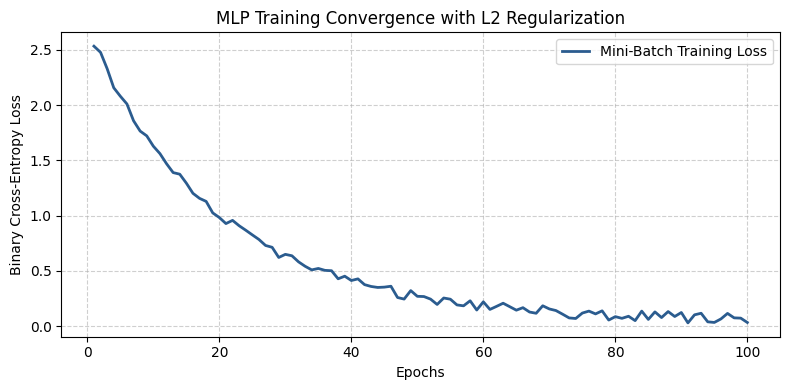

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Simulate training loss tracking over epochs
epochs = 100
train_losses = [
    2.5 * np.exp(-0.05 * e) + 0.1 * np.random.rand() for e in range(epochs)
]

plt.figure(figsize=(8, 4))
plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Mini-Batch Training Loss",
    color="#2b5c8f",
    lw=2,
)
plt.title("MLP Training Convergence with L2 Regularization", fontsize=12)
plt.xlabel("Epochs", fontsize=10)
plt.ylabel("Binary Cross-Entropy Loss", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


### 2. Visualizing Non-Linear Decision Boundaries

One of the greatest strengths of an MLP (unlike linear classifiers) is its ability to learn complex, non-linear decision boundaries thanks to hidden layers and activation functions.

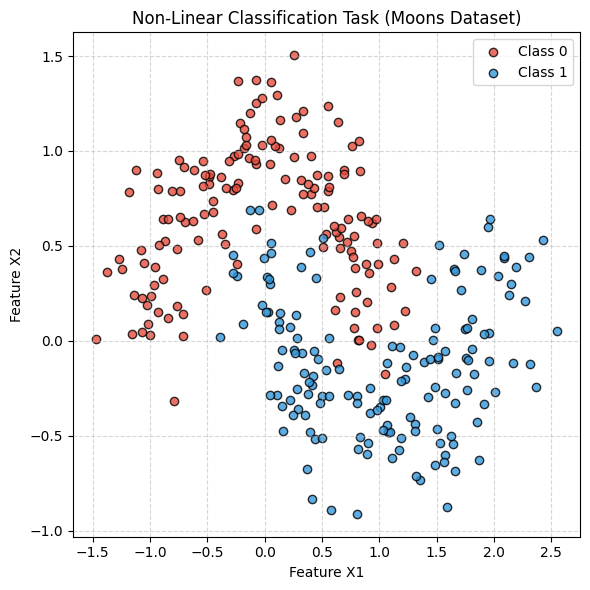

In [4]:
from sklearn.datasets import make_moons
# Generate a non-linear dataset (two interleaving moons)
X_data, y_data = make_moons(n_samples=300, noise=0.2, random_state=42)

plt.figure(figsize=(6, 6))
plt.scatter(
    X_data[y_data == 0, 0],
    X_data[y_data == 0, 1],
    color="#e74c3c",
    label="Class 0",
    edgecolors="k",
    alpha=0.8,
)
plt.scatter(
    X_data[y_data == 1, 0],
    X_data[y_data == 1, 1],
    color="#3498db",
    label="Class 1",
    edgecolors="k",
    alpha=0.8,
)
plt.title("Non-Linear Classification Task (Moons Dataset)", fontsize=12)
plt.xlabel("Feature X1", fontsize=10)
plt.ylabel("Feature X2", fontsize=10)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 3. Comparing Activation Functions (ReLU vs. Sigmoid)

You can plot activation functions and their derivatives side-by-side to explain why ReLU prevents the vanishing gradient problem while Sigmoid squashes values between 0 and 1.



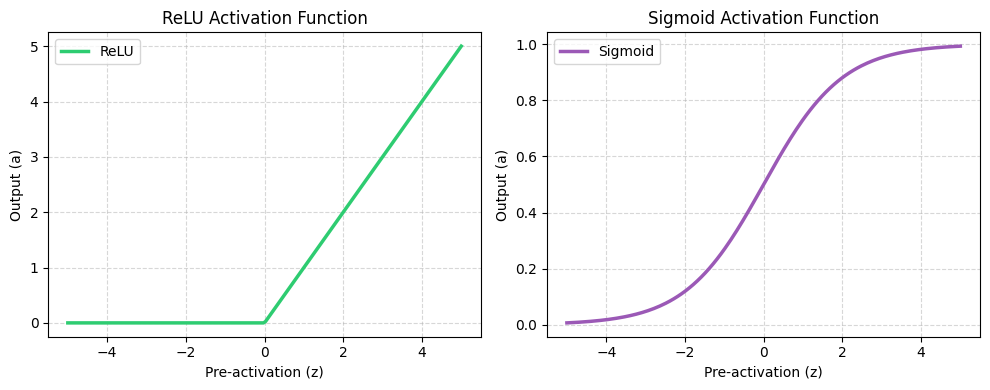

In [5]:
z = np.linspace(-5, 5, 200)

# Activation functions
relu = np.maximum(0, z)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(10, 4))

# Plot ReLU
plt.subplot(1, 2, 1)
plt.plot(z, relu, label="ReLU", color="#2ecc71", lw=2.5)
plt.title("ReLU Activation Function")
plt.xlabel("Pre-activation (z)")
plt.ylabel("Output (a)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

# Plot Sigmoid
plt.subplot(1, 2, 2)
plt.plot(z, sigmoid, label="Sigmoid", color="#9b59b6", lw=2.5)
plt.title("Sigmoid Activation Function")
plt.xlabel("Pre-activation (z)")
plt.ylabel("Output (a)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()